# Tails of the storm-peak 10 m wind on coarsened sampling grids

The same 0.25° tracks are used for every dataset; only the field they are sampled from changes. ERA5 `u10` and `v10` are remapped **bilinearly** to 1.25°, 1.875°, 2.5° and 3.0°. `ws10 = hypot(u10, v10)` is then computed on each grid (`statistics_on_tracks.add_derived_fields`), and the maximum is taken within 500 km of every track point. `ws10_max_max` is the largest of these over the lifetime of the storm: **one storm peak per track and sampling grid**.

So every storm has five paired values, and the questions are:

1. **How large** is the attenuation of the storm peak at each grid, and does it **grow with intensity**? (storm-level, section 4)
2. Does the **shape of the tail** change, i.e. does coarsening push the tail towards a bound (more negative ξ), and how much do high **return levels** drop? (EVT, sections 5–7)

### The second theorem of Extreme Value Theory 
#### Pickands-Balkema-de Haan

Above a selected threshold, the excess of a distribution (the tail), should follow a Generalized Pareto Distribution (GPD) for decay. 

$F(y) = 1 - (1 + \frac{\xi y}{\sigma})^{\frac{-1}{\xi}}$

Wherein:
- a positive $\xi$ represents a heavy tail, for a power law distributed decay
- $\xi$ = 0 (or going to 0) represents an exponential decay
- a negative $\xi$ represents a bounded tail with a finite end point

Fitting our tails to these distributions will tell us of the difference in fit parameters, and can help us in our analysis of the caps on variables in different distributions.

#### Why a significance test alone is not the question

A bilinearly interpolated value is a weighted mean of the four surrounding native values (non-negative weights summing to one), so it can never exceed the largest of them. For the same storm, the coarse peak is therefore ≤ the native peak (apart from edge effects at the 500 km circle). Any paired test will find a highly significant difference. What matters is the **size** of the effect and whether it is **larger for the strongest storms**. Effect sizes with paired-bootstrap intervals are reported throughout instead of p-values.

Two mechanisms lower the coarse peak:
* **Sparser sampling:** bilinear remapping evaluates the native field at fewer points. A compact wind maximum can fall between the coarse points.
* **Component cancellation:** `u10` and `v10` are interpolated separately, and speed is computed afterwards. Where the wind turns within a coarse cell, the components partly cancel, so the speed is lower than an interpolated speed would be.

**Note on the grids.** The target grids start at 0°E and 90°N, like ERA5 (`regrid_era5.write_grid_file`). 1.25°, 2.5° and 3° are whole multiples of 0.25° (5, 10 and 12 steps), so every point of these grids **coincides** with a native grid point. Bilinear remapping then just picks every 5th, 10th or 12th native value: pure sub-sampling, with no averaging and no component cancellation. Only 1.875° (7.5 steps) has points between native points, where it really interpolates (and cancellation can occur). The losses on 1.25°, 2.5° and 3° are therefore caused only by the sparser sampling.

Neither of these is a *model* effect: a coarse model would also have different dynamics. This is the **representation** of the same ERA5 field on a coarser grid.

#### Plan
1. Setup and functions (all functions are collected in section 2, so they can be moved to a module).
2. Loading and sanity checks: pairing, the "coarse ≤ native" check, grid points inside the radius.
3. Distributions in the style of `example_cases/example_distributions.ipynb`.
4. Storm-level attenuation: ratio R = coarse peak / native peak against native intensity.
5. EVT threshold choice: mean residual life and parameter-stability plots.
6. GPD fits per grid, diagnostics, return levels.
7. Paired bootstrap of the differences to native, and a trend model ξ(Δx), σ(Δx).

## 1. Setup

In [55]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

module_dir = (Path.cwd() / ".." / ".." / "algorithms").resolve()
sys.path.insert(0, str(module_dir))
from configs import SAMPLE_CONFIG
from helpers import haversine_km
from plotting import setup_plotting

colors = setup_plotting()
plt.rcParams["axes.formatter.limits"] = (-4, 5)   # plain numbers on the axes

`VAR` is the per-track column that is analysed; `gust10_max_max` can be used instead to repeat everything for gusts. Return periods are counted in **DJF seasons** (a "20-season" peak is exceeded by one storm every 20 winters on average).

In [56]:
DATA_DIR = Path("/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/regrid_exp")
TRACK_RES = "0p25"                 # grid the tracking was done on (same tracks for all sampling grids)
VAR = "ws10_max_max"               # storm peak: max over the lifetime of the max within the radius
VAR_LABEL = "storm-peak 10 m wind (m s$^{-1}$)"
RADIUS_KM = SAMPLE_CONFIG["radius_km"]
NATIVE = 0.25

GALE, STORM = 17.2, 24.5           # m s-1, Beaufort 8 and 10
RETURN_PERIODS = (5, 10, 20, 50)   # DJF seasons
N_BOOT = 1000                      # bootstrap replicates
SEED = 42

## 2. Functions

### 2.1 Loading and sanity checks

In [57]:
def res_from_tag(tag):
    # '0p25' -> 0.25, '1p875' -> 1.875
    return float(tag.replace("p", "."))


def res_label(res):
    return f"{res:g}°"


def season_dirs(data_dir=DATA_DIR):
    return sorted(p for p in Path(data_dir).glob("*_DJF") if not p.name.startswith("._"))


def load_summaries(data_dir=DATA_DIR, track_res=TRACK_RES):
    """All per-track summary CSVs (every season and sampling grid) in one table with 'season' and 'res' columns."""
    tables = []
    for season_dir in season_dirs(data_dir):
        for path in sorted(season_dir.glob(f"*_{track_res}_vo_summary_sl*.csv")):
            df = pd.read_csv(path, parse_dates=["start_time", "end_time"])
            df.insert(0, "season", season_dir.name)
            df.insert(1, "res", res_from_tag(path.stem.split("_sl")[-1]))
            tables.append(df)
    return pd.concat(tables, ignore_index=True)


def paired_table(summary, var=VAR):
    """One row per storm (season, track_id), one column per sampling grid. Storms with a NaN at any grid are dropped."""
    wide = summary.pivot(index=["season", "track_id"], columns="res", values=var)
    n_nan = int(wide.isna().any(axis=1).sum())
    if n_nan:
        print(f"dropped {n_nan} storms with NaN at one or more grids")
    return wide.dropna().sort_index(axis=1)


def exceedance_check(peaks, native=NATIVE, tol=1e-6):
    """Bilinear remapping cannot create larger maxima: count storms whose coarse peak exceeds the native peak."""
    rows = {}
    for r in peaks.columns.drop(native):
        excess = peaks[r] - peaks[native]
        rows[res_label(r)] = {"storms": len(peaks),
                              "coarse > native": int((excess > tol).sum()),
                              "largest excess (m/s)": round(float(excess.max()), 4)}
    return pd.DataFrame(rows).T


def peak_positions(data_dir=DATA_DIR, track_res=TRACK_RES, sample_tag="sl0p25", var="ws10_max"):
    """Position of every storm at the time step of its native peak wind (from the points CSVs)."""
    tables = []
    for season_dir in season_dirs(data_dir):
        path = season_dir / f"{season_dir.name}_{track_res}_vo_points_{sample_tag}.csv"
        p = pd.read_csv(path, usecols=["track_id", "time", "lat", "lon", var]).dropna(subset=[var])
        p = p.loc[p.groupby("track_id")[var].idxmax()]
        p.insert(0, "season", season_dir.name)
        tables.append(p)
    return pd.concat(tables).set_index(["season", "track_id"])


def grid_points_in_radius(lat0, lon0, res, radius_km=RADIUS_KM):
    """
    Number of points of the global res° grid within radius_km of (lat0, lon0).
    The grid is the one of regrid_era5.write_grid_file: longitudes from 0, latitudes from 90 to -90.
    """
    lats = 90 - res * np.arange(round(180 / res) + 1)
    lats = lats[np.abs(lats - lat0) <= radius_km / 111.0 + res]
    lons = res * np.arange(round(360 / res))
    dist = haversine_km(lat0, lon0, lats[:, None], lons[None, :])
    return int((dist <= radius_km).sum())

### 2.2 Storm-level attenuation

`attenuation_stats` summarises the paired ratio R = coarse / native for each grid:
* `median R` and `median loss` (native − coarse, m s⁻¹) over all storms;
* `R top10% − R mid` and `R top5% − R mid`: median R of the storms in the top 10 % (5 %) of native intensity minus median R of the middle half (25–75 %). **Negative means the strongest storms lose a larger fraction**, which is the "diminished extremes" effect;
* `slope R per 10 m/s`: least-squares slope of R against the native peak.

`bootstrap` resamples storms (or whole seasons) with replacement, keeping each storm's five values together, and applies any statistic to every resample.

In [58]:
def ratio_table(peaks, native=NATIVE):
    """R = coarse peak / native peak per storm (columns: coarse grids)."""
    return peaks.drop(columns=native).div(peaks[native], axis=0)


def binned_quantiles(x, y, edges, qs=(0.1, 0.25, 0.5, 0.75, 0.9)):
    """Quantiles of y in bins of x. Returns one row per bin with the median x of the bin as 'x'."""
    b = pd.cut(x, edges, include_lowest=True)
    out = y.groupby(b, observed=True).quantile(list(qs)).unstack()
    out.insert(0, "n", y.groupby(b, observed=True).size())
    out.insert(0, "x", x.groupby(b, observed=True).median())
    return out.reset_index(drop=True)


def attenuation_stats(peaks, native=NATIVE, mid=(0.25, 0.75), tops=(0.90, 0.95)):
    nat = peaks[native]
    R = ratio_table(peaks, native)
    loss = -(peaks.drop(columns=native).sub(nat, axis=0))
    mid_mask = nat.between(nat.quantile(mid[0]), nat.quantile(mid[1]))
    out = pd.DataFrame({"median R": R.median(), "median loss (m/s)": loss.median()})
    for t in tops:
        out[f"R top{100 - 100 * t:g}% − R mid"] = R[nat >= nat.quantile(t)].median() - R[mid_mask].median()
    xc = nat - nat.mean()
    out["slope R per 10 m/s"] = 10 * (R.mul(xc, axis=0).sum() / (xc ** 2).sum())
    out.index.name = "res"
    return out


def resampler(peaks, by="storm", seed=SEED):
    """Function that returns one paired resample of the storms (rows keep all grids together)."""
    rng = np.random.default_rng(seed)
    values, cols = peaks.to_numpy(), peaks.columns
    if by == "storm":
        def draw():
            return pd.DataFrame(values[rng.integers(0, len(values), len(values))], columns=cols)
    elif by == "season":
        seasons = peaks.index.get_level_values("season")
        blocks = [values[seasons == s] for s in seasons.unique()]

        def draw():
            idx = rng.integers(0, len(blocks), len(blocks))
            return pd.DataFrame(np.concatenate([blocks[i] for i in idx]), columns=cols)
    else:
        raise ValueError("by must be 'storm' or 'season'")
    return draw


def bootstrap(peaks, stat, n_boot=N_BOOT, by="storm", seed=SEED):
    """Apply stat(resample) to n_boot paired resamples. Returns the results concatenated with a 'boot' index level."""
    draw = resampler(peaks, by=by, seed=seed)
    return pd.concat([stat(draw()) for _ in range(n_boot)], keys=range(n_boot), names=["boot"])


def with_ci(point, boot, ci=0.95, decimals=3):
    """Point estimates with percentile intervals from bootstrap (same index/columns as point)."""
    lo = boot.groupby(level=point.index.name).quantile((1 - ci) / 2)
    hi = boot.groupby(level=point.index.name).quantile(1 - (1 - ci) / 2)
    fmt = lambda e, l, h: f"{e:.{decimals}f} [{l:.{decimals}f}, {h:.{decimals}f}]"
    return pd.DataFrame({c: [fmt(point.loc[i, c], lo.loc[i, c], hi.loc[i, c]) for i in point.index]
                         for c in point.columns}, index=[res_label(i) for i in point.index])

### 2.3 Generalized Pareto distribution

* `fit_gpd`: maximum likelihood for the excesses y = x − u, started from the probability-weighted-moment estimate (`gpd_pwm`, Hosking & Wallis 1987). It agrees with `scipy.stats.genpareto.fit(y, floc=0)` (scipy's `c` is ξ) but is faster and robust for the bootstrap.
* `gpd_cov`: asymptotic covariance of (ξ, σ). Valid only for ξ > −0.5; below that the MLE is irregular and only bootstrap intervals should be used.
* `moment_estimator`: Dekkers–Einmahl–de Haan moment estimator of ξ from the top k order statistics. It is valid for all ξ and is a cross-check on the MLE (the Hill estimator is not, since it assumes ξ > 0).
* `sigma*` = σ − ξu is the **modified scale**. For a GPD tail it does not depend on the threshold, so it can be compared across grids even when their thresholds differ.
* Return level for T seasons: $x_T = u + \frac{\sigma}{\xi}\left[(\lambda T)^{\xi} - 1\right]$, with λ the number of exceedances per season.

In [59]:
def gpd_cdf(y, xi, sigma):
    """F(y) = 1 - (1 + xi y / sigma)^(-1/xi); the exponential limit for xi -> 0."""
    y = np.asarray(y, dtype=float)
    if abs(xi) < 1e-8:
        return 1 - np.exp(-y / sigma)
    return 1 - np.maximum(1 + xi * y / sigma, 0) ** (-1 / xi)


def gpd_ppf(p, xi, sigma):
    p = np.asarray(p, dtype=float)
    if abs(xi) < 1e-8:
        return -sigma * np.log1p(-p)
    return sigma / xi * ((1 - p) ** (-xi) - 1)


def gpd_nll(params, y):
    xi, log_sigma = params
    sigma = np.exp(log_sigma)
    z = 1 + xi * y / sigma
    if np.any(z <= 0):
        return np.inf
    if abs(xi) < 1e-8:
        return len(y) * log_sigma + y.sum() / sigma
    return len(y) * log_sigma + (1 + 1 / xi) * np.log(z).sum()


def gpd_pwm(y):
    """Probability-weighted-moment estimate (xi, sigma) of the GPD of the excesses y."""
    y = np.sort(np.asarray(y, dtype=float))
    n = len(y)
    a0 = y.mean()
    a1 = np.sum((n - 1 - np.arange(n)) / (n - 1) * y) / n      # E[Y (1 - F(Y))]
    xi = 2 - a0 / (a0 - 2 * a1)
    sigma = 2 * a0 * a1 / (a0 - 2 * a1)
    return xi, sigma


def fit_gpd(y):
    """Maximum-likelihood (xi, sigma) of the GPD of the excesses y > 0."""
    y = np.asarray(y, dtype=float)
    xi0, s0 = gpd_pwm(y)
    if not (np.isfinite(xi0) and np.isfinite(s0) and s0 > 0):
        xi0, s0 = 0.0, y.mean()
    xi0 = max(xi0, -0.9)
    if xi0 < 0 and y.max() >= -s0 / xi0:          # start inside the support
        s0 = -xi0 * y.max() * 1.05
    res = optimize.minimize(gpd_nll, [xi0, np.log(s0)], args=(y,), method="Nelder-Mead",
                            options={"xatol": 1e-6, "fatol": 1e-8, "maxiter": 2000})
    return res.x[0], np.exp(res.x[1])


def gpd_cov(xi, sigma, n):
    """Asymptotic covariance of (xi, sigma) from the Fisher information (Smith 1984), xi > -0.5."""
    return (1 + xi) / n * np.array([[1 + xi, -sigma], [-sigma, 2 * sigma ** 2]])


def moment_estimator(x, k):
    """Dekkers-Einmahl-de Haan moment estimator of xi from the k largest values of a positive sample x."""
    x = np.sort(np.asarray(x, dtype=float))[::-1]
    logs = np.log(x[:k]) - np.log(x[k])
    m1, m2 = logs.mean(), (logs ** 2).mean()
    return m1 + 1 - 0.5 / (1 - m1 ** 2 / m2)


def return_level(T, u, xi, sigma, rate):
    """Level exceeded on average once every T seasons; rate = exceedances of u per season."""
    m = np.asarray(T, dtype=float) * rate
    if abs(xi) < 1e-8:
        return u + sigma * np.log(m)
    return u + sigma / xi * (m ** xi - 1)


def upper_endpoint(u, xi, sigma):
    return u - sigma / xi if xi < 0 else np.inf

### 2.4 Tail fits for all grids

Two ways to choose the threshold, answering different questions:
* `mode="quantile"`: the q-quantile **of each grid**. The overall downward shift is removed, so differences are in the **shape** of the tail (ξ, σ*). Every grid has the same number of exceedances.
* `mode="fixed"`: one physical threshold for all grids (Poisson–GPD). Coarse grids have **fewer** exceedances, and the return levels combine the lower rate with the tail shape. This is the hazard view.

In the bootstrap, the quantile thresholds are recomputed in every resample.

In [60]:
def tail_thresholds(peaks, mode="quantile", q=0.90, u_fixed=None):
    if mode == "quantile":
        return {r: float(np.quantile(peaks[r], q)) for r in peaks.columns}
    if mode == "fixed":
        return {r: float(u_fixed) for r in peaks.columns}
    raise ValueError("mode must be 'quantile' or 'fixed'")


def fit_tail(x, u, n_seasons, return_periods=RETURN_PERIODS):
    x = np.asarray(x, dtype=float)
    y = x[x > u] - u
    xi, sigma = fit_gpd(y)
    rate = len(y) / n_seasons
    out = {"u": u, "n_exc": len(y), "rate": rate, "xi": xi, "sigma": sigma, "sigma*": sigma - xi * u,
           "endpoint": upper_endpoint(u, xi, sigma)}
    for T in return_periods:
        out[f"RL{T}"] = float(return_level(T, u, xi, sigma, rate))
    return out


def fit_all(peaks, n_seasons, mode="quantile", q=0.90, u_fixed=None):
    """GPD fit for every grid (column of peaks). Returns one row per grid."""
    thr = tail_thresholds(peaks, mode, q, u_fixed)
    out = pd.DataFrame({r: fit_tail(peaks[r], thr[r], n_seasons) for r in peaks.columns}).T
    out.index.name = "res"
    return out


def differences_to_native(fits, native=NATIVE):
    """fits (one row per grid, or with a 'boot' level) minus the native row."""
    if isinstance(fits.index, pd.MultiIndex):
        return fits - fits.xs(native, level="res").reindex(fits.index, level="boot")
    return fits - fits.loc[native]


def stability_table(x, quantiles, n_seasons):
    """xi and sigma* (with asymptotic standard errors) and the moment estimator over a range of thresholds."""
    x = np.asarray(x, dtype=float)
    rows = []
    for q in quantiles:
        u = np.quantile(x, q)
        f = fit_tail(x, u, n_seasons)
        cov = gpd_cov(f["xi"], f["sigma"], f["n_exc"])
        grad = np.array([-u, 1.0])                       # d sigma* / d(xi, sigma)
        rows.append({"q": q, "u": u, "n_exc": f["n_exc"], "xi": f["xi"], "xi_se": np.sqrt(cov[0, 0]),
                     "sigma*": f["sigma*"], "sigma*_se": np.sqrt(grad @ cov @ grad),
                     "xi_moment": moment_estimator(x, f["n_exc"])})
    return pd.DataFrame(rows)


def mean_residual_life(x, thresholds):
    """Mean excess over u with a 95 % normal interval. Linear in u above a threshold where the GPD holds."""
    x = np.asarray(x, dtype=float)
    rows = []
    for u in thresholds:
        y = x[x > u] - u
        if len(y) < 10:
            break
        rows.append({"u": u, "mean_excess": y.mean(), "ci": 1.96 * y.std(ddof=1) / np.sqrt(len(y)), "n": len(y)})
    return pd.DataFrame(rows)

### 2.5 Trend over grid spacing

All exceedances of all grids are fitted together with
ξ = ξ₀ + ξ₁ · ln(Δx / 0.25°) and ln σ = s₀ + s₁ · ln(Δx / 0.25°),
so ξ₀, s₀ describe the native grid and ξ₁, s₁ the change per e-fold of grid spacing. ξ₁ < 0 means that coarser grids push the tail towards a bound. Because the grids are paired, the joint likelihood is not a true likelihood (the samples are not independent), so the point estimates are fine but the intervals must come from the paired bootstrap, not from the Hessian or a likelihood-ratio test.

In [61]:
def fit_gpd_trend(peaks, mode="quantile", q=0.90, u_fixed=None, native=NATIVE):
    thr = tail_thresholds(peaks, mode, q, u_fixed)
    ys, zs = [], []
    for r, u in thr.items():
        x = peaks[r].to_numpy()
        ys.append(x[x > u] - u)
        zs.append(np.full((x > u).sum(), np.log(r / native)))
    y, z = np.concatenate(ys), np.concatenate(zs)

    def nll(theta):
        xi = theta[0] + theta[1] * z
        log_sigma = theta[2] + theta[3] * z
        t = 1 + xi * y / np.exp(log_sigma)
        if np.any(t <= 0):
            return np.inf
        xi = np.where(np.abs(xi) < 1e-8, 1e-8, xi)
        return np.sum(log_sigma + (1 + 1 / xi) * np.log(t))

    xi0, s0 = fit_gpd(ys[list(thr).index(native)])
    res = optimize.minimize(nll, [xi0, 0.0, np.log(s0), 0.0], method="Nelder-Mead",
                            options={"xatol": 1e-6, "fatol": 1e-8, "maxiter": 4000})
    return pd.Series(res.x, index=["xi0", "xi1", "s0", "s1"])

## 3. Data and sanity checks

### 3.1 Loading

In [62]:
summary = load_summaries()
peaks = paired_table(summary)                    # rows: storms, columns: sampling grids

RESOLUTIONS = list(peaks.columns)
COARSE = [r for r in RESOLUTIONS if r != NATIVE]
SEASONS = sorted(peaks.index.get_level_values("season").unique())
N_SEASONS = len(SEASONS)
RES_COLOR = {r: colors[i % len(colors)] for i, r in enumerate(RESOLUTIONS)}

print(f"{len(peaks)} storms in {N_SEASONS} DJF seasons ({SEASONS[0][:4]}–{SEASONS[-1][4:8]}), "
      f"{len(peaks) / N_SEASONS:.0f} per season")
print("sampling grids:", [res_label(r) for r in RESOLUTIONS])
peaks.describe().round(2)

5549 storms in 47 DJF seasons (1979–2026), 118 per season
sampling grids: ['0.25°', '1.25°', '1.875°', '2.5°', '3°']


res,0.250,1.250,1.875,2.500,3.000
count,5549.00,5549.00,5549.00,5549.00,5549.00
mean,21.16,20.22,19.66,19.36,18.98
std,4.72,4.56,4.56,4.45,4.40
min,8.01,6.85,6.70,6.49,6.38
25%,17.80,17.01,16.43,16.26,15.84
50%,20.80,19.96,19.40,19.21,18.88
75%,24.31,23.35,22.75,22.40,22.04
max,39.92,36.89,36.89,36.12,36.04


All seasons start in 1998, so the whole period is in the satellite era. The pre-1979 sensitivity check only becomes relevant if the analysis is extended back to 1940.

### 3.2 Coarse peak ≤ native peak

This should be zero, or almost zero with tiny excesses from grid points just inside the 500 km circle on the coarse grid whose native neighbours lie just outside it. Larger numbers would point to a problem in the sampling (coordinates, radius or remapping weights).

In [63]:
exceedance_check(peaks)

,storms,coarse > native,largest excess (m/s)
1.25°,5549.0,0.0,0.0000
1.875°,5549.0,3.0,0.3667
2.5°,5549.0,0.0,0.0000
3°,5549.0,0.0,0.0000


### 3.3 Grid points inside the sampling circle

At the time step of each storm's native peak wind, the number of grid points of each sampling grid within 500 km. On coarse grids the storm peak is a maximum over few values, so where the grid points happen to fall relative to the wind maximum adds noise to the attenuation.

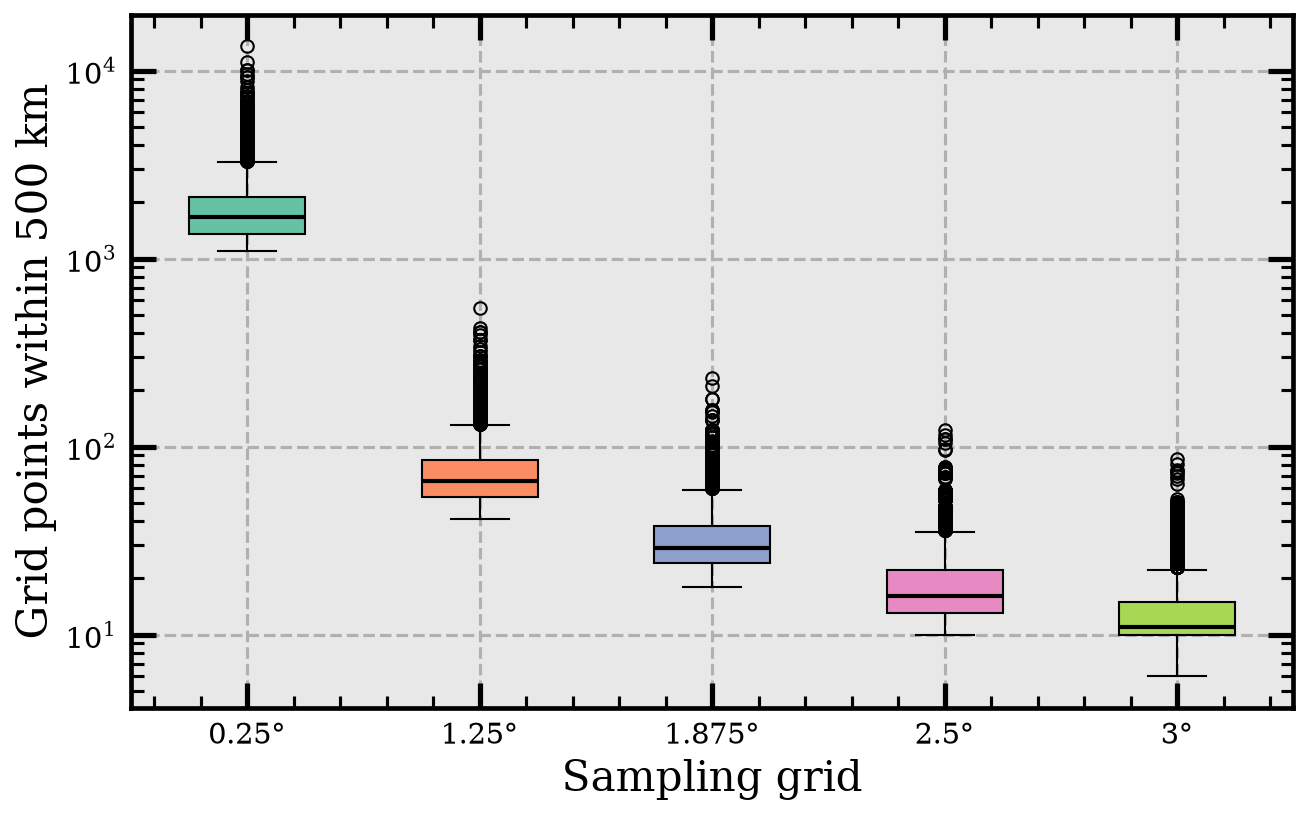

,min,5%,50%,95%,max
0.25°,1101,1215,1657,3763,13427
1.25°,41,48,66,150,544
1.875°,18,21,29,67,232
2.5°,10,12,16,38,122
3°,6,8,11,26,86


In [64]:
pos = peak_positions().reindex(peaks.index)
n_in_radius = pd.DataFrame({r: [grid_points_in_radius(la, lo, r) for la, lo in zip(pos["lat"], pos["lon"])]
                            for r in RESOLUTIONS}, index=peaks.index)

fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot([n_in_radius[r] for r in RESOLUTIONS], patch_artist=True, medianprops={"color": "k", "lw": 2})
for patch, r in zip(bp["boxes"], RESOLUTIONS):
    patch.set_facecolor(RES_COLOR[r])
ax.set_yscale("log")
ax.set_xticks(range(1, len(RESOLUTIONS) + 1), [res_label(r) for r in RESOLUTIONS])
ax.set(xlabel="Sampling grid", ylabel=f"Grid points within {RADIUS_KM} km")
plt.show()

n_in_radius.describe(percentiles=[0.05, 0.5, 0.95]).T[["min", "5%", "50%", "95%", "max"]] \
    .rename(index=res_label).astype(int)

## AC.

Here a box plot of available wind speeds inside each radius of search, for the five different grid resolutions. 

## 4. Distributions and storm-level attenuation

### 4.1 Distributions (as in `example_distributions.ipynb`, 4.2 and 4.5)

Left: the storm-peak wind for each sampling grid, with the gale (17.2 m s⁻¹) and storm (24.5 m s⁻¹) thresholds. Right: box plots (box = interquartile range, whiskers = 1.5 × IQR).

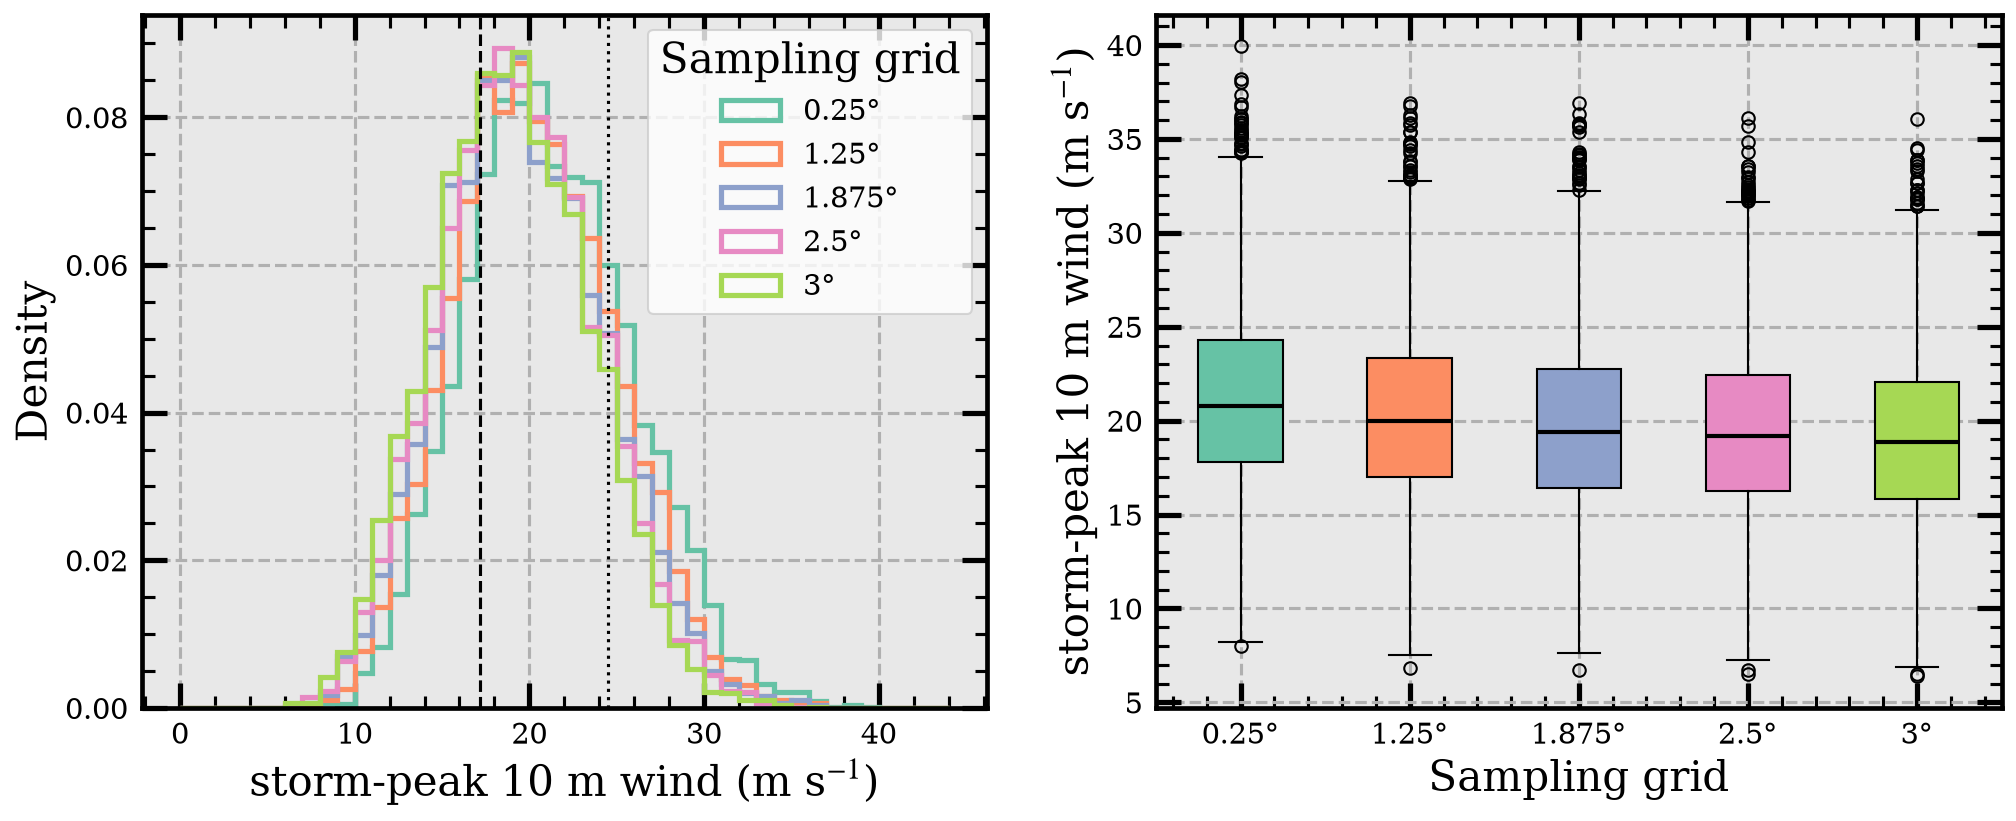

,fraction ≥ gale,fraction ≥ storm,max (m/s)
res,,,
0.25°,0.795,0.236,39.924
1.25°,0.736,0.179,36.889
1.875°,0.691,0.150,36.889
2.5°,0.676,0.129,36.122
3°,0.643,0.112,36.037


In [65]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
bins = np.arange(0, 45, 1)
for r in RESOLUTIONS:
    ax1.hist(peaks[r], bins=bins, density=True, histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.axvline(GALE, color="k", ls="--", lw=1.5)
ax1.axvline(STORM, color="k", ls=":", lw=1.5)
ax1.set(xlabel=VAR_LABEL, ylabel="Density")
ax1.legend(title="Sampling grid")

bp = ax2.boxplot([peaks[r] for r in RESOLUTIONS], patch_artist=True, medianprops={"color": "k", "lw": 2})
for patch, r in zip(bp["boxes"], RESOLUTIONS):
    patch.set_facecolor(RES_COLOR[r])
ax2.set_xticks(range(1, len(RESOLUTIONS) + 1), [res_label(r) for r in RESOLUTIONS])
ax2.set(xlabel="Sampling grid", ylabel=VAR_LABEL)
plt.show()

pd.DataFrame({"fraction ≥ gale": (peaks >= GALE).mean(), "fraction ≥ storm": (peaks >= STORM).mean(),
              "max (m/s)": peaks.max()}).rename(index=res_label).round(3)

## AC:

Here we see distributions of wind speeds for each sampling resolution. We have representations of the density plot, and also the box plot for each.

Quantile–quantile plots against the native grid. Left: percentiles 1 … 99. Right: the upper tail, percentiles 90 … 99.9. Points below the 1:1 line mean the coarse grid has weaker storms at that percentile. A gap that widens towards the top means the tail is compressed more than the bulk.

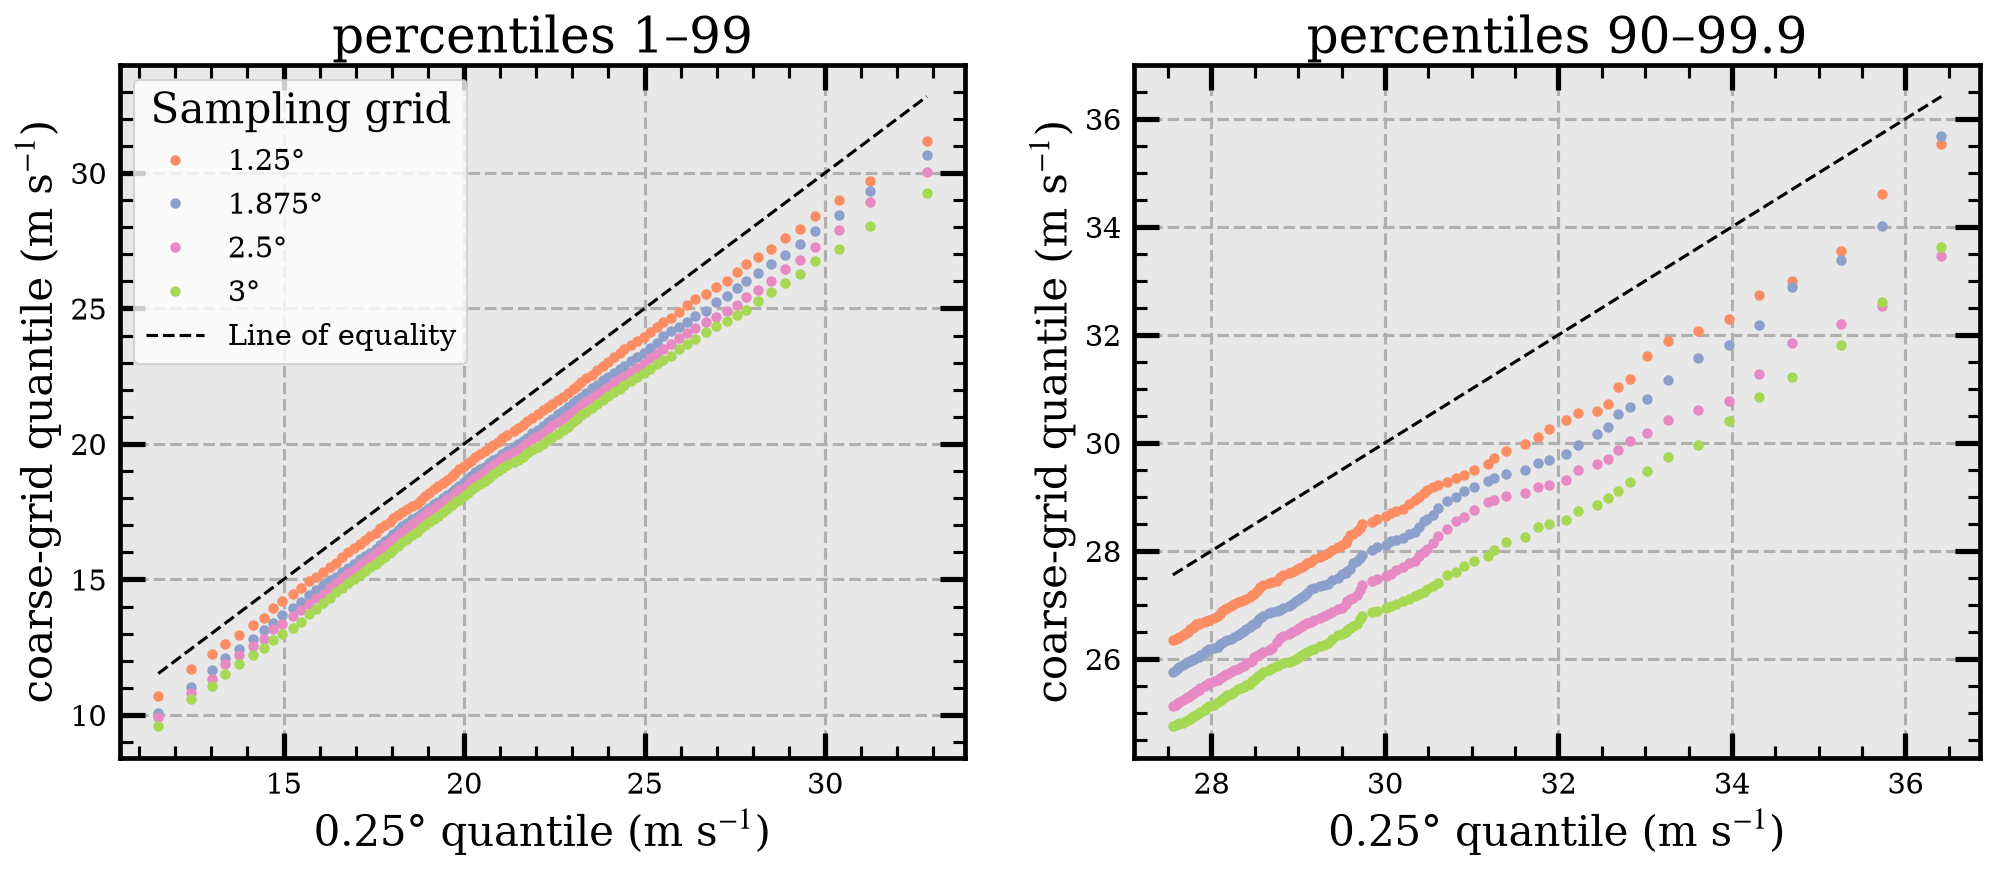

In [66]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for ax, q in ((ax1, np.arange(1, 100)), (ax2, np.arange(90, 99.95, 0.1))):
    ref = np.percentile(peaks[NATIVE], q)
    for r in COARSE:
        ax.plot(ref, np.percentile(peaks[r], q), "o", ms=4, color=RES_COLOR[r], label=res_label(r))
    ax.plot([ref.min(), ref.max()], [ref.min(), ref.max()], "k--", lw=1.5, label = 'Line of equality')
    ax.set(xlabel=f"{res_label(NATIVE)} quantile (m s$^{{-1}}$)", ylabel="coarse-grid quantile (m s$^{-1}$)")
ax1.set_title("percentiles 1–99")
ax2.set_title("percentiles 90–99.9")
ax1.legend(title="Sampling grid")
plt.show()

## AC: 

This describes, for each value found in both coarse and fine grid, the correspondence between weakest-weakest all the way up to strongest-strongest. The dashed black line is the theoretical 'identical distributions' line. Values under line are lower in y-axis, values over the line are larger in y-value. We see here a systematic shift towards weaker values for each further coarsening of the grid. This shift is larger for high wind speeds, than for the weaker winds. 

### 4.2 Paired peaks

Each dot is one storm: its peak on a coarse grid against its native peak. If coarsening only shifted everything down, the cloud would run parallel to the 1:1 line. Flattening at the top would mean the strongest storms are compressed. The black line is the median in bins of native intensity.

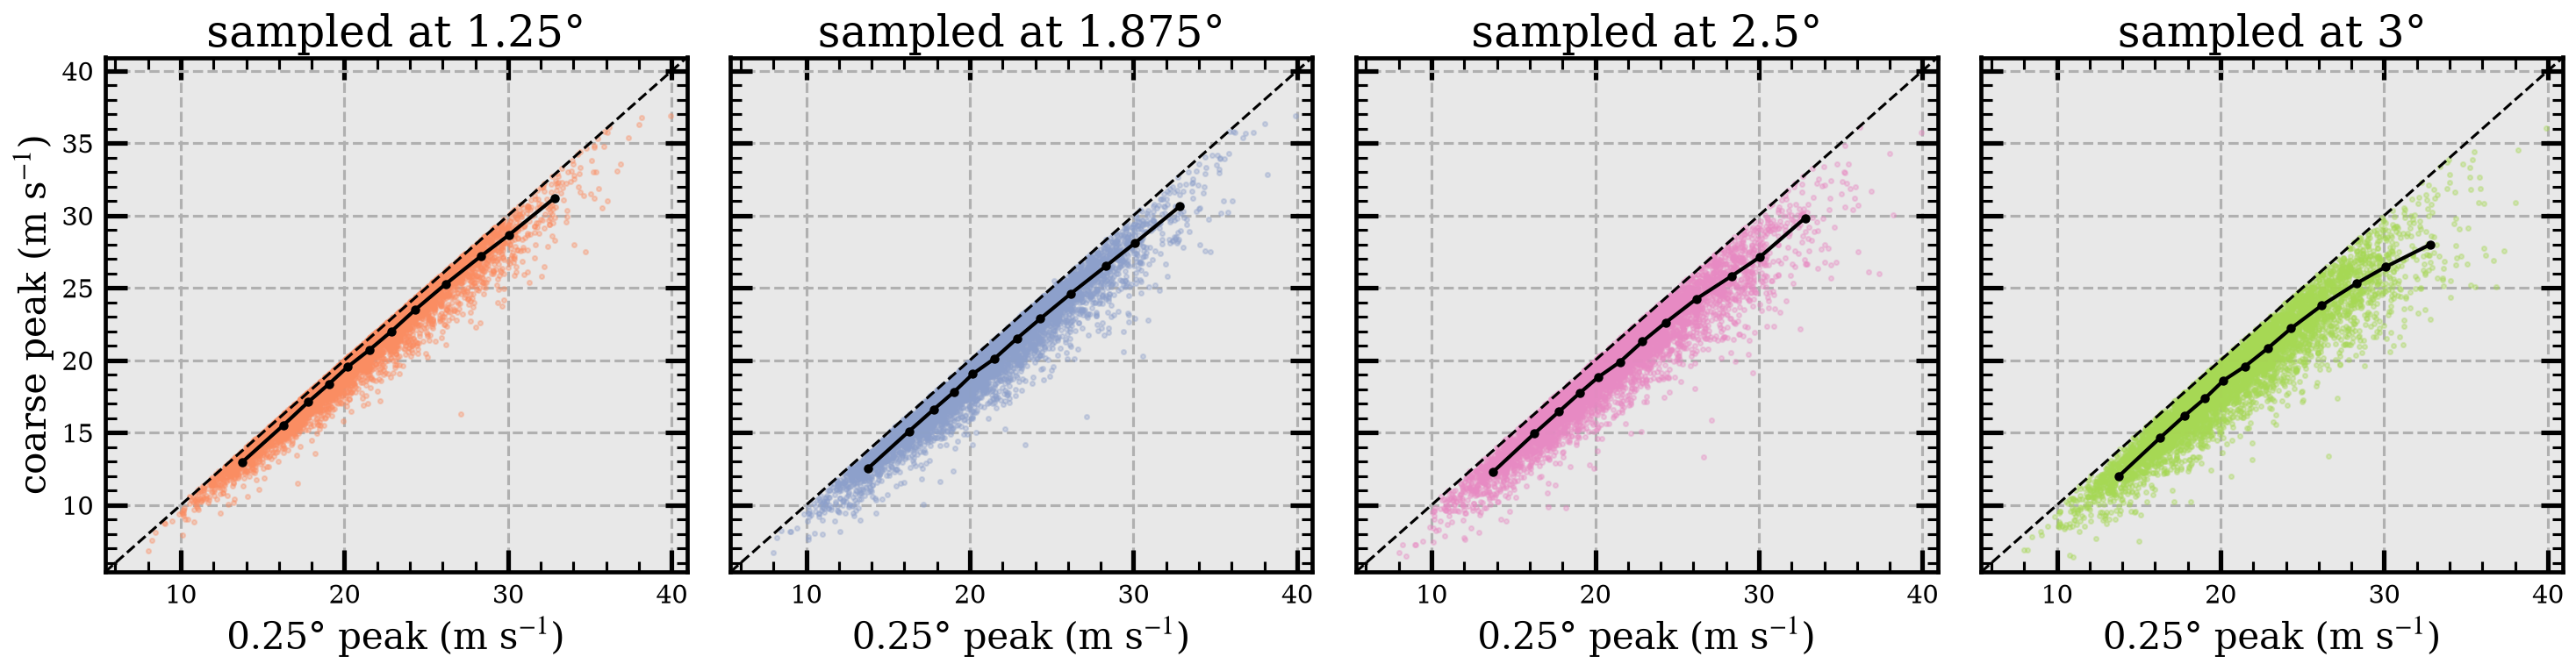

In [67]:
edges = np.quantile(peaks[NATIVE], [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, .95, .98, 1])
lims = [peaks.min().min() - 1, peaks.max().max() + 1]

fig, axes = plt.subplots(1, len(COARSE), figsize=(20, 5.5), sharex=True, sharey=True)
for ax, r in zip(axes, COARSE):
    ax.scatter(peaks[NATIVE], peaks[r], s=6, alpha=0.35, color=RES_COLOR[r], rasterized=True)
    bq = binned_quantiles(peaks[NATIVE], peaks[r], edges)
    ax.plot(bq["x"], bq[0.5], "k-o", ms=4, lw=2)
    ax.plot(lims, lims, "k--", lw=1.5)
    ax.set(xlim=lims, ylim=lims, title=f"sampled at {res_label(r)}", xlabel=f"{res_label(NATIVE)} peak (m s$^{{-1}}$)")
axes[0].set_ylabel("coarse peak (m s$^{-1}$)")
fig.tight_layout()
plt.show()

## AC:

Peak-matching for each resolution against the 0.25 $\deg$. This shows us that higher values are more dampened than low values. Meaning, high wind speeds will experience a stronger diminishing in coarse resolution than low values will. 

### 4.3 Ratio R = coarse / native against native intensity

This is the most direct answer to "are the extremes diminished more?". It uses every storm, not only those above a threshold. Lines: median R in bins of native intensity (deciles, then the top 5 % and top 2 %). Bands: 25–75 % of the storms in the bin. Right: the same as an absolute loss in m s⁻¹.

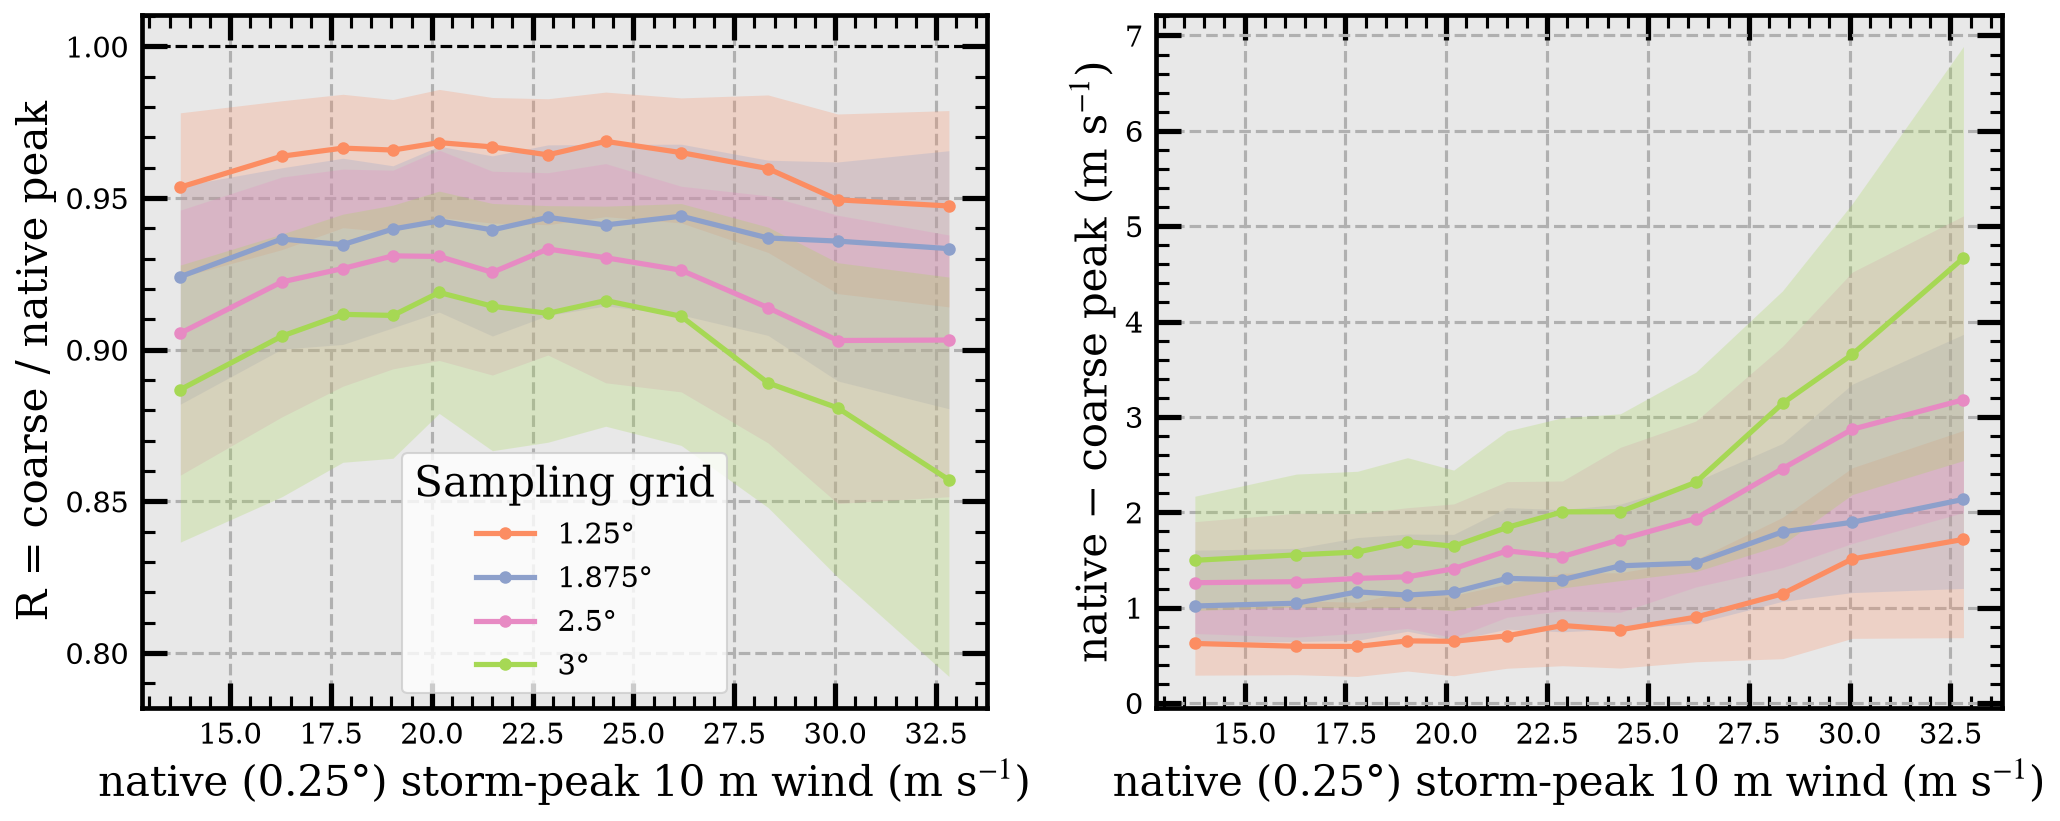

In [68]:
R = ratio_table(peaks)
loss = -(peaks[COARSE].sub(peaks[NATIVE], axis=0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for r in COARSE:
    for ax, y in ((ax1, R[r]), (ax2, loss[r])):
        bq = binned_quantiles(peaks[NATIVE], y, edges)
        ax.fill_between(bq["x"], bq[0.25], bq[0.75], color=RES_COLOR[r], alpha=0.25, lw=0)
        ax.plot(bq["x"], bq[0.5], "-o", ms=5, lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.axhline(1, color="k", ls="--", lw=1.5)
ax1.set(xlabel=f"native ({res_label(NATIVE)}) {VAR_LABEL}", ylabel="R = coarse / native peak")
ax2.set(xlabel=f"native ({res_label(NATIVE)}) {VAR_LABEL}", ylabel="native − coarse peak (m s$^{-1}$)")
ax1.legend(title="Sampling grid")
plt.show()

The same in numbers, with 95 % paired-bootstrap intervals (resampling storms). The contrasts `R top…% − R mid` are the key quantities: an interval entirely below zero means the strongest storms are attenuated **disproportionately**.

In [69]:
att_point = attenuation_stats(peaks)
att_boot = bootstrap(peaks, lambda s: attenuation_stats(s), n_boot=N_BOOT)
with_ci(att_point, att_boot)

,median R,median loss (m/s),R top10% − R mid,R top5% − R mid,slope R per 10 m/s
1.25°,"0.964 [0.963, 0.966]","0.724 [0.703, 0.746]","-0.012 [-0.015, -0.006]","-0.018 [-0.022, -0.009]","0.001 [-0.002, 0.003]"
1.875°,"0.938 [0.937, 0.939]","1.261 [1.225, 1.295]","-0.004 [-0.010, 0.000]","-0.007 [-0.012, 0.003]","0.009 [0.006, 0.012]"
2.5°,"0.925 [0.923, 0.927]","1.531 [1.496, 1.571]","-0.024 [-0.031, -0.015]","-0.028 [-0.037, -0.014]","0.001 [-0.002, 0.006]"
3°,"0.909 [0.906, 0.911]","1.842 [1.807, 1.885]","-0.033 [-0.042, -0.024]","-0.044 [-0.056, -0.029]","0.001 [-0.003, 0.006]"


Part of the extra loss in the top bins is the mechanism itself: storms with a high native peak are often those with a sharp, compact wind maximum, and that is exactly what a sparse grid misses. With so few grid points inside the circle at 2.5° and 3° (section 3.3), the alignment of the grid relative to the maximum also becomes important.

## 5. EVT: choice of threshold

### 5.1 Mean residual life

Above a threshold where the GPD holds, the mean excess E[X − u | X > u] is linear in u, with slope ξ / (1 − ξ). A downward slope means ξ < 0 (a bounded tail).

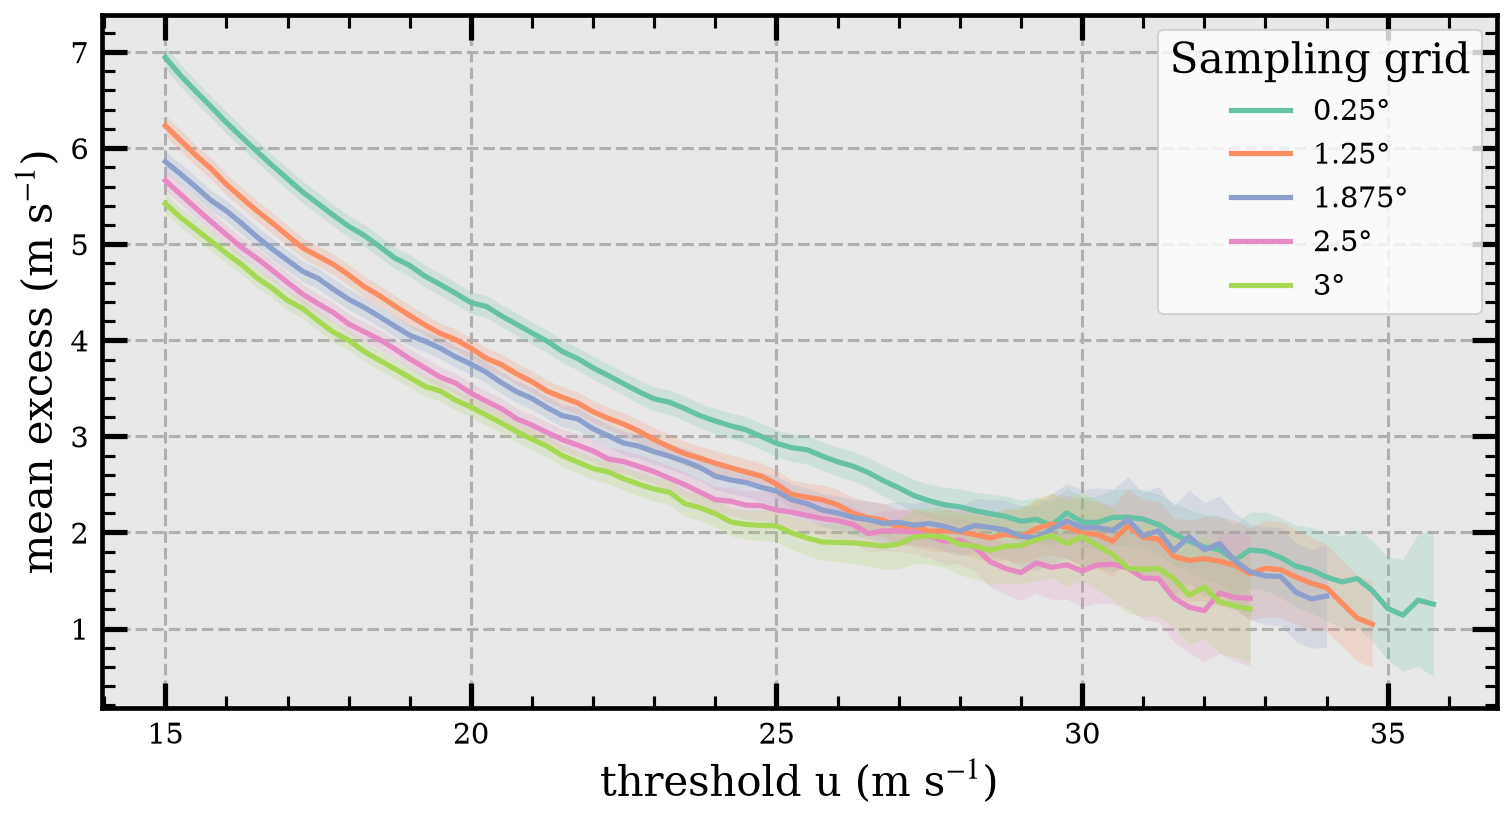

In [70]:
fig, ax = plt.subplots(figsize=(12, 6))
for r in RESOLUTIONS:
    mrl = mean_residual_life(peaks[r], np.arange(15, 38, 0.25))
    ax.fill_between(mrl["u"], mrl["mean_excess"] - mrl["ci"], mrl["mean_excess"] + mrl["ci"],
                    color=RES_COLOR[r], alpha=0.2, lw=0)
    ax.plot(mrl["u"], mrl["mean_excess"], lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax.set(xlabel="threshold u (m s$^{-1}$)", ylabel="mean excess (m s$^{-1}$)")
ax.legend(title="Sampling grid")
plt.show()

### 5.2 Parameter stability

ξ and σ* fitted at thresholds from the 70th to the 97th percentile of each grid, with ±1.96 asymptotic standard errors. Above a suitable threshold both should be constant within their uncertainty. The dashed line is the moment estimator of ξ (cross-check on the MLE). The threshold quantile is on the x axis, so the grids can be compared at the same number of exceedances (top axis).

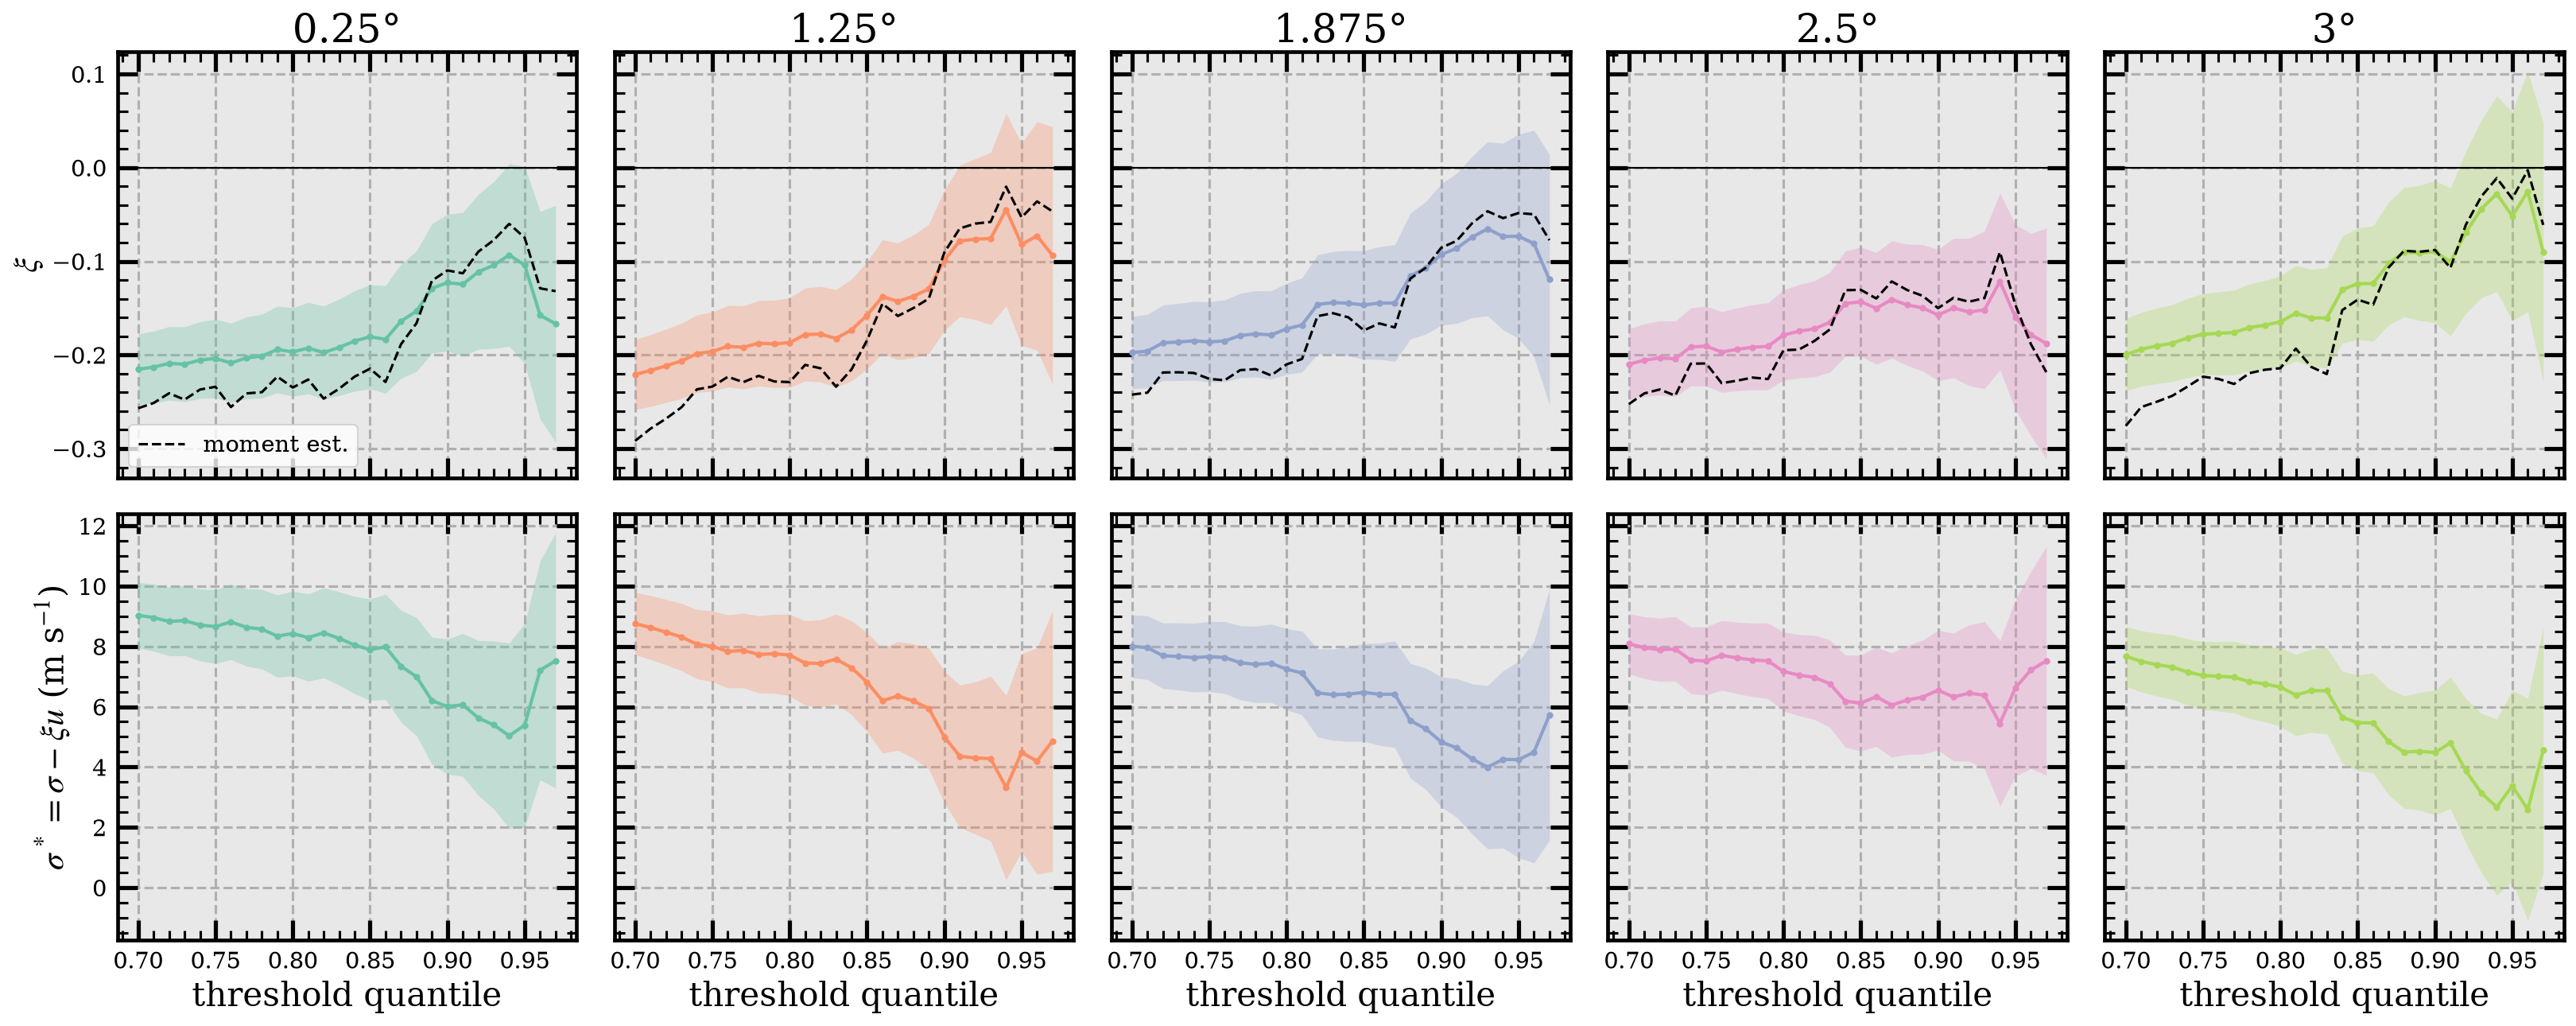

,0.25°,1.25°,1.875°,2.5°,3°
threshold (m/s) at quantile,,,,,
0.80,25.15,24.12,23.55,23.16,22.77
0.85,26.19,25.11,24.51,24.10,23.70
0.90,27.56,26.35,25.76,25.12,24.75
0.95,29.30,27.92,27.38,26.79,26.26


In [71]:
STAB_Q = np.round(np.arange(0.70, 0.971, 0.01), 2)
stab = {r: stability_table(peaks[r], STAB_Q, N_SEASONS) for r in RESOLUTIONS}

fig, axes = plt.subplots(2, len(RESOLUTIONS), figsize=(22, 9), sharex=True, sharey="row")
for j, r in enumerate(RESOLUTIONS):
    s = stab[r]
    for i, (p, label) in enumerate((("xi", r"$\xi$"), ("sigma*", r"$\sigma^* = \sigma - \xi u$ (m s$^{-1}$)"))):
        ax = axes[i, j]
        ax.fill_between(s["q"], s[p] - 1.96 * s[f"{p}_se"], s[p] + 1.96 * s[f"{p}_se"], color=RES_COLOR[r], alpha=0.3, lw=0)
        ax.plot(s["q"], s[p], "-o", ms=3, lw=2, color=RES_COLOR[r])
        if p == "xi":
            ax.plot(s["q"], s["xi_moment"], "k--", lw=1.5, label="moment est.")
            ax.axhline(0, color="k", lw=1)
            ax.set_title(res_label(r))
        if j == 0:
            ax.set_ylabel(label)
    axes[1, j].set_xlabel("threshold quantile")
axes[0, 0].legend(loc="lower left")
fig.tight_layout()
plt.show()

pd.DataFrame({res_label(r): stab[r].set_index("q").loc[[0.8, 0.85, 0.9, 0.95], "u"] for r in RESOLUTIONS}).round(2) \
    .rename_axis("threshold (m/s) at quantile")

### 5.3 Chosen thresholds

`Q_TAIL` is used for the shape comparison (each grid above its own quantile). `U_FIXED` is the physical threshold for the hazard view. It is set close to the native 90th percentile, so the native fit is comparable between the two approaches. Check in the plots above that both lie in the stable range. The final results should be repeated for a few neighbouring thresholds (section 7.4).

In [72]:
Q_TAIL = 0.90
U_FIXED = 27.5     # m s-1, ~ native 90th percentile

pd.DataFrame({"quantile threshold (m/s)": tail_thresholds(peaks, "quantile", Q_TAIL),
              "exceedances of quantile thr.": {r: int((peaks[r] > tail_thresholds(peaks, "quantile", Q_TAIL)[r]).sum()) for r in RESOLUTIONS},
              f"exceedances of {U_FIXED} m/s": (peaks > U_FIXED).sum()}).rename(index=res_label).round(2)

,quantile threshold (m/s),exceedances of quantile thr.,exceedances of 27.5 m/s
0.25°,27.56,555,569
1.25°,26.35,555,345
1.875°,25.76,555,261
2.5°,25.12,555,201
3°,24.75,555,141


## 6. GPD fits per sampling grid

### 6.1 Diagnostics

Quantile plots of the exceedances over the per-grid `Q_TAIL` threshold: empirical against fitted GPD quantiles. Points on the 1:1 line mean the GPD describes the tail well.

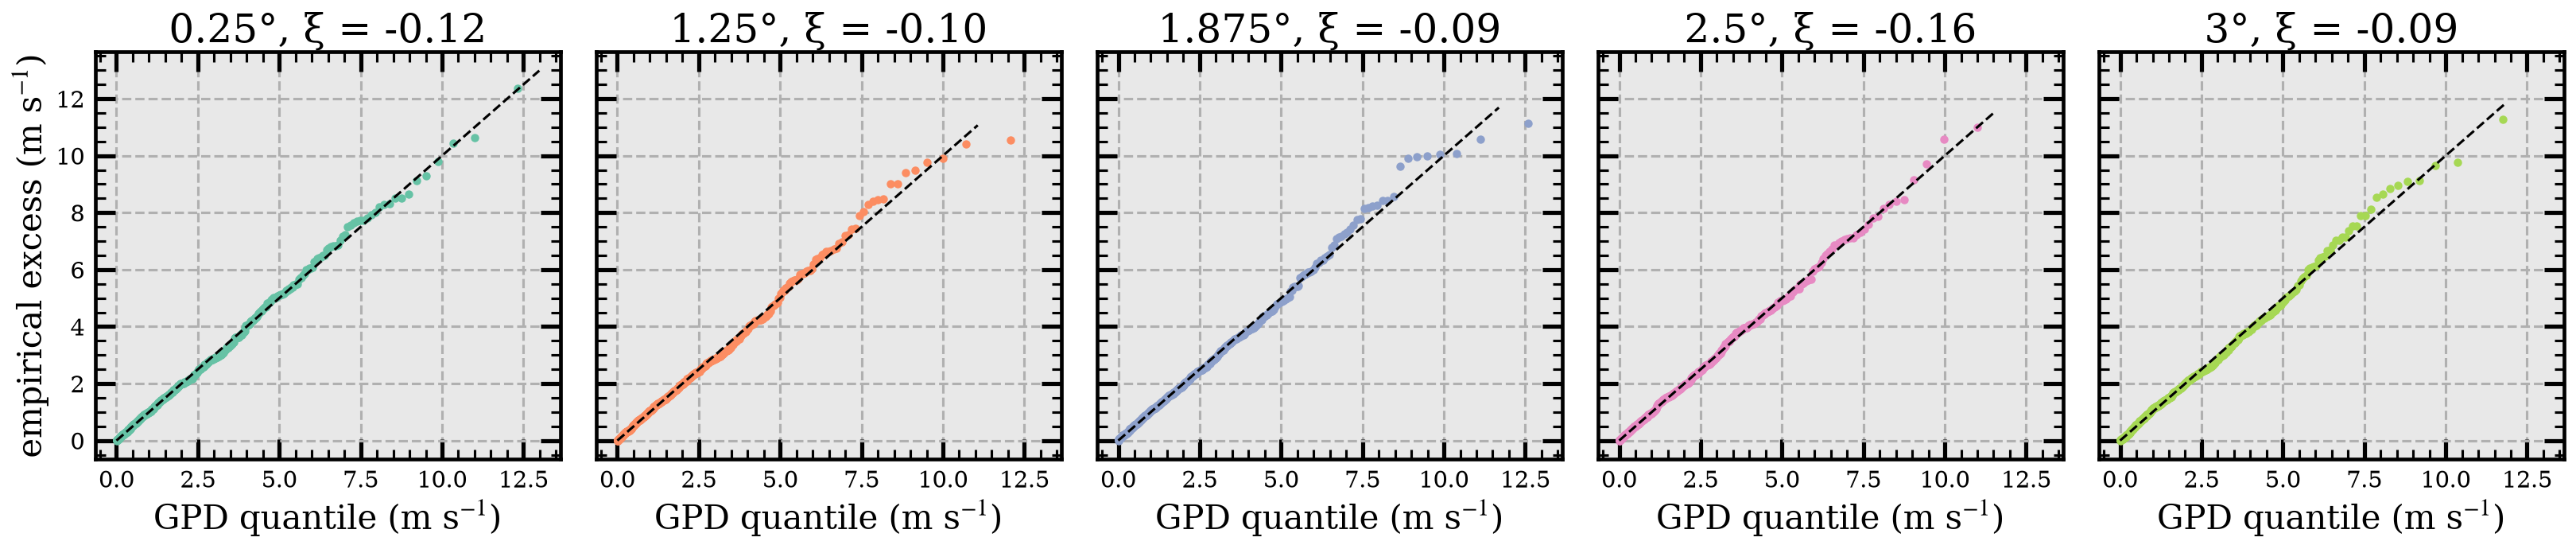

In [73]:
fits_q = fit_all(peaks, N_SEASONS, mode="quantile", q=Q_TAIL)

fig, axes = plt.subplots(1, len(RESOLUTIONS), figsize=(22, 5), sharex=True, sharey=True)
for ax, r in zip(axes, RESOLUTIONS):
    f = fits_q.loc[r]
    y = np.sort(peaks[r][peaks[r] > f["u"]] - f["u"])
    p = (np.arange(1, len(y) + 1) - 0.5) / len(y)
    ax.plot(gpd_ppf(p, f["xi"], f["sigma"]), y, "o", ms=4, color=RES_COLOR[r])
    top = y.max() * 1.05
    ax.plot([0, top], [0, top], "k--", lw=1.5)
    ax.set(title=f"{res_label(r)}, ξ = {f['xi']:.2f}", xlabel="GPD quantile (m s$^{-1}$)")
axes[0].set_ylabel("empirical excess (m s$^{-1}$)")
fig.tight_layout()
plt.show()

### 6.2 Fitted parameters

Two tables: per-grid quantile thresholds (shape view) and the fixed physical threshold (hazard view). `RLT` is the T-season return level, i.e. the storm peak exceeded on average once every T winters. `endpoint` is the implied upper bound u − σ/ξ (only for ξ < 0). It is extremely uncertain for ξ close to zero and should not be over-interpreted.

In [74]:
cols = ["u", "n_exc", "rate", "xi", "sigma", "sigma*", "endpoint"] + [f"RL{T}" for T in RETURN_PERIODS]
print(f"Per-grid {Q_TAIL:.0%} quantile threshold")
display(fits_q[cols].rename(index=res_label).astype(float).round(3))

fits_f = fit_all(peaks, N_SEASONS, mode="fixed", u_fixed=U_FIXED)
print(f"Fixed threshold {U_FIXED} m/s")
display(fits_f[cols].rename(index=res_label).astype(float).round(3))

Per-grid 90% quantile threshold


,u,n_exc,rate,xi,sigma,sigma*,endpoint,RL5,RL10,RL20,RL50
res,,,,,,,,,,,
0.25°,27.556,555.0,11.809,-0.123,2.620,6.005,48.880,35.959,37.014,37.983,39.143
1.25°,26.347,555.0,11.809,-0.099,2.390,4.997,50.496,34.367,35.436,36.435,37.654
1.875°,25.756,555.0,11.809,-0.093,2.443,4.834,52.076,34.051,35.174,36.227,37.519
2.5°,25.123,555.0,11.809,-0.157,2.593,6.547,41.598,32.927,33.824,34.627,35.563
3°,24.750,555.0,11.809,-0.090,2.259,4.480,49.928,32.466,33.519,34.508,35.725


Fixed threshold 27.5 m/s


,u,n_exc,rate,xi,sigma,sigma*,endpoint,RL5,RL10,RL20,RL50
res,,,,,,,,,,,
0.25°,27.5,569.0,12.106,-0.119,2.609,5.888,49.378,35.965,37.029,38.008,39.185
1.25°,27.5,345.0,7.340,-0.059,2.134,3.755,63.690,34.426,35.598,36.723,38.141
1.875°,27.5,261.0,5.553,-0.084,2.272,4.579,54.573,34.089,35.246,36.338,37.688
2.5°,27.5,201.0,4.277,-0.180,2.321,7.278,40.372,32.961,33.832,34.600,35.479
3°,27.5,141.0,3.000,-0.138,2.242,6.040,43.740,32.566,33.586,34.513,35.609


## 7. Paired bootstrap: differences to the native grid

Storms are resampled with replacement, keeping each storm's five peaks together, and all five GPDs are refitted on every resample. The storm-to-storm variability is shared by all grids, so it cancels in the **differences** to native, and those are much more precise than the separate intervals of each grid. Intervals are 95 % percentile intervals. The number of seasons is held fixed, so the exceedance rate in a resample is (exceedances in the resample) / `N_SEASONS`.

In [75]:
boot_q = bootstrap(peaks, lambda s: fit_all(s, N_SEASONS, mode="quantile", q=Q_TAIL))
boot_f = bootstrap(peaks, lambda s: fit_all(s, N_SEASONS, mode="fixed", u_fixed=U_FIXED))

### 7.1 Parameters and differences, per-grid quantile threshold (tail shape)

In [76]:
PARAMS = ["xi", "sigma*", "RL10", "RL20", "RL50"]
print("Estimates")
display(with_ci(fits_q[PARAMS].astype(float), boot_q[PARAMS].astype(float)))
print(f"Difference to {res_label(NATIVE)} (coarse − native)")
display(with_ci(differences_to_native(fits_q[PARAMS].astype(float)).loc[COARSE],
                differences_to_native(boot_q[PARAMS].astype(float)).drop(index=NATIVE, level="res")))

Estimates


,xi,sigma*,RL10,RL20,RL50
0.25°,"-0.123 [-0.203, -0.052]","6.005 [3.833, 8.505]","37.014 [36.078, 38.038]","37.983 [36.845, 39.270]","39.143 [37.654, 40.853]"
1.25°,"-0.099 [-0.177, -0.033]","4.997 [3.079, 7.306]","35.436 [34.535, 36.401]","36.435 [35.297, 37.714]","37.654 [36.164, 39.360]"
1.875°,"-0.093 [-0.172, -0.021]","4.834 [2.749, 7.088]","35.174 [34.220, 36.199]","36.227 [35.062, 37.565]","37.519 [36.001, 39.325]"
2.5°,"-0.157 [-0.231, -0.084]","6.547 [4.479, 8.627]","33.824 [32.972, 34.682]","34.627 [33.591, 35.718]","35.563 [34.253, 36.998]"
3°,"-0.090 [-0.160, -0.022]","4.480 [2.602, 6.377]","33.519 [32.593, 34.458]","34.508 [33.382, 35.712]","35.725 [34.257, 37.287]"


Difference to 0.25° (coarse − native)


,xi,sigma*,RL10,RL20,RL50
1.25°,"0.024 [-0.040, 0.086]","-1.007 [-2.943, 0.959]","-1.578 [-2.158, -1.008]","-1.548 [-2.330, -0.773]","-1.489 [-2.609, -0.421]"
1.875°,"0.030 [-0.040, 0.103]","-1.171 [-3.313, 0.962]","-1.840 [-2.412, -1.192]","-1.756 [-2.535, -0.859]","-1.624 [-2.733, -0.356]"
2.5°,"-0.035 [-0.107, 0.050]","0.542 [-1.962, 2.706]","-3.190 [-3.956, -2.361]","-3.356 [-4.383, -2.256]","-3.579 [-4.962, -2.119]"
3°,"0.033 [-0.042, 0.115]","-1.525 [-4.042, 0.691]","-3.495 [-4.354, -2.690]","-3.474 [-4.588, -2.408]","-3.418 [-4.974, -1.970]"


### 7.2 Parameters and differences, fixed threshold (hazard)

Here the exceedance rate (storms per season above `U_FIXED`) falls on coarser grids, and the return levels include this.

In [77]:
PARAMS_F = ["rate", "xi", "sigma*", "RL10", "RL20", "RL50"]
print("Estimates")
display(with_ci(fits_f[PARAMS_F].astype(float), boot_f[PARAMS_F].astype(float)))
print(f"Difference to {res_label(NATIVE)} (coarse − native)")
display(with_ci(differences_to_native(fits_f[PARAMS_F].astype(float)).loc[COARSE],
                differences_to_native(boot_f[PARAMS_F].astype(float)).drop(index=NATIVE, level="res")))

Estimates


,rate,xi,sigma*,RL10,RL20,RL50
0.25°,"12.106 [11.191, 13.043]","-0.119 [-0.197, -0.046]","5.888 [3.706, 8.286]","37.029 [36.092, 38.055]","38.008 [36.853, 39.301]","39.185 [37.683, 40.945]"
1.25°,"7.340 [6.616, 8.106]","-0.059 [-0.163, 0.039]","3.755 [0.810, 6.867]","35.598 [34.630, 36.609]","36.723 [35.458, 38.124]","38.141 [36.391, 40.203]"
1.875°,"5.553 [4.915, 6.213]","-0.084 [-0.187, 0.019]","4.579 [1.471, 7.756]","35.246 [34.282, 36.264]","36.338 [35.153, 37.716]","37.688 [36.083, 39.735]"
2.5°,"4.277 [3.681, 4.851]","-0.180 [-0.323, -0.079]","7.278 [4.248, 11.618]","33.832 [32.950, 34.613]","34.600 [33.484, 35.582]","35.479 [34.055, 36.776]"
3°,"3.000 [2.511, 3.489]","-0.138 [-0.308, 0.007]","6.040 [1.495, 11.338]","33.586 [32.675, 34.461]","34.513 [33.350, 35.535]","35.609 [34.116, 37.140]"


Difference to 0.25° (coarse − native)


,rate,xi,sigma*,RL10,RL20,RL50
1.25°,"-4.766 [-5.426, -4.149]","0.060 [-0.020, 0.136]","-2.132 [-4.478, 0.351]","-1.431 [-2.046, -0.821]","-1.285 [-2.157, -0.393]","-1.044 [-2.307, 0.336]"
1.875°,"-6.553 [-7.298, -5.830]","0.035 [-0.063, 0.128]","-1.308 [-4.201, 1.839]","-1.782 [-2.358, -1.134]","-1.670 [-2.483, -0.730]","-1.497 [-2.756, -0.091]"
2.5°,"-7.830 [-8.660, -7.106]","-0.061 [-0.191, 0.035]","1.391 [-1.521, 5.385]","-3.197 [-3.948, -2.378]","-3.408 [-4.502, -2.355]","-3.706 [-5.251, -2.317]"
3°,"-9.106 [-9.979, -8.340]","-0.019 [-0.167, 0.117]","0.152 [-4.070, 4.708]","-3.443 [-4.264, -2.790]","-3.496 [-4.503, -2.615]","-3.576 [-4.981, -2.294]"


### 7.3 Return levels and the trend with grid spacing

Left: return-level curves with 95 % bootstrap bands (fixed threshold) and the empirical storm peaks (the i-th largest peak at return period `N_SEASONS` / (i − 0.44)). Right: ξ for each grid (per-grid quantile threshold, 95 % paired-bootstrap intervals), with the trend model ξ = ξ₀ + ξ₁ ln(Δx / 0.25°).

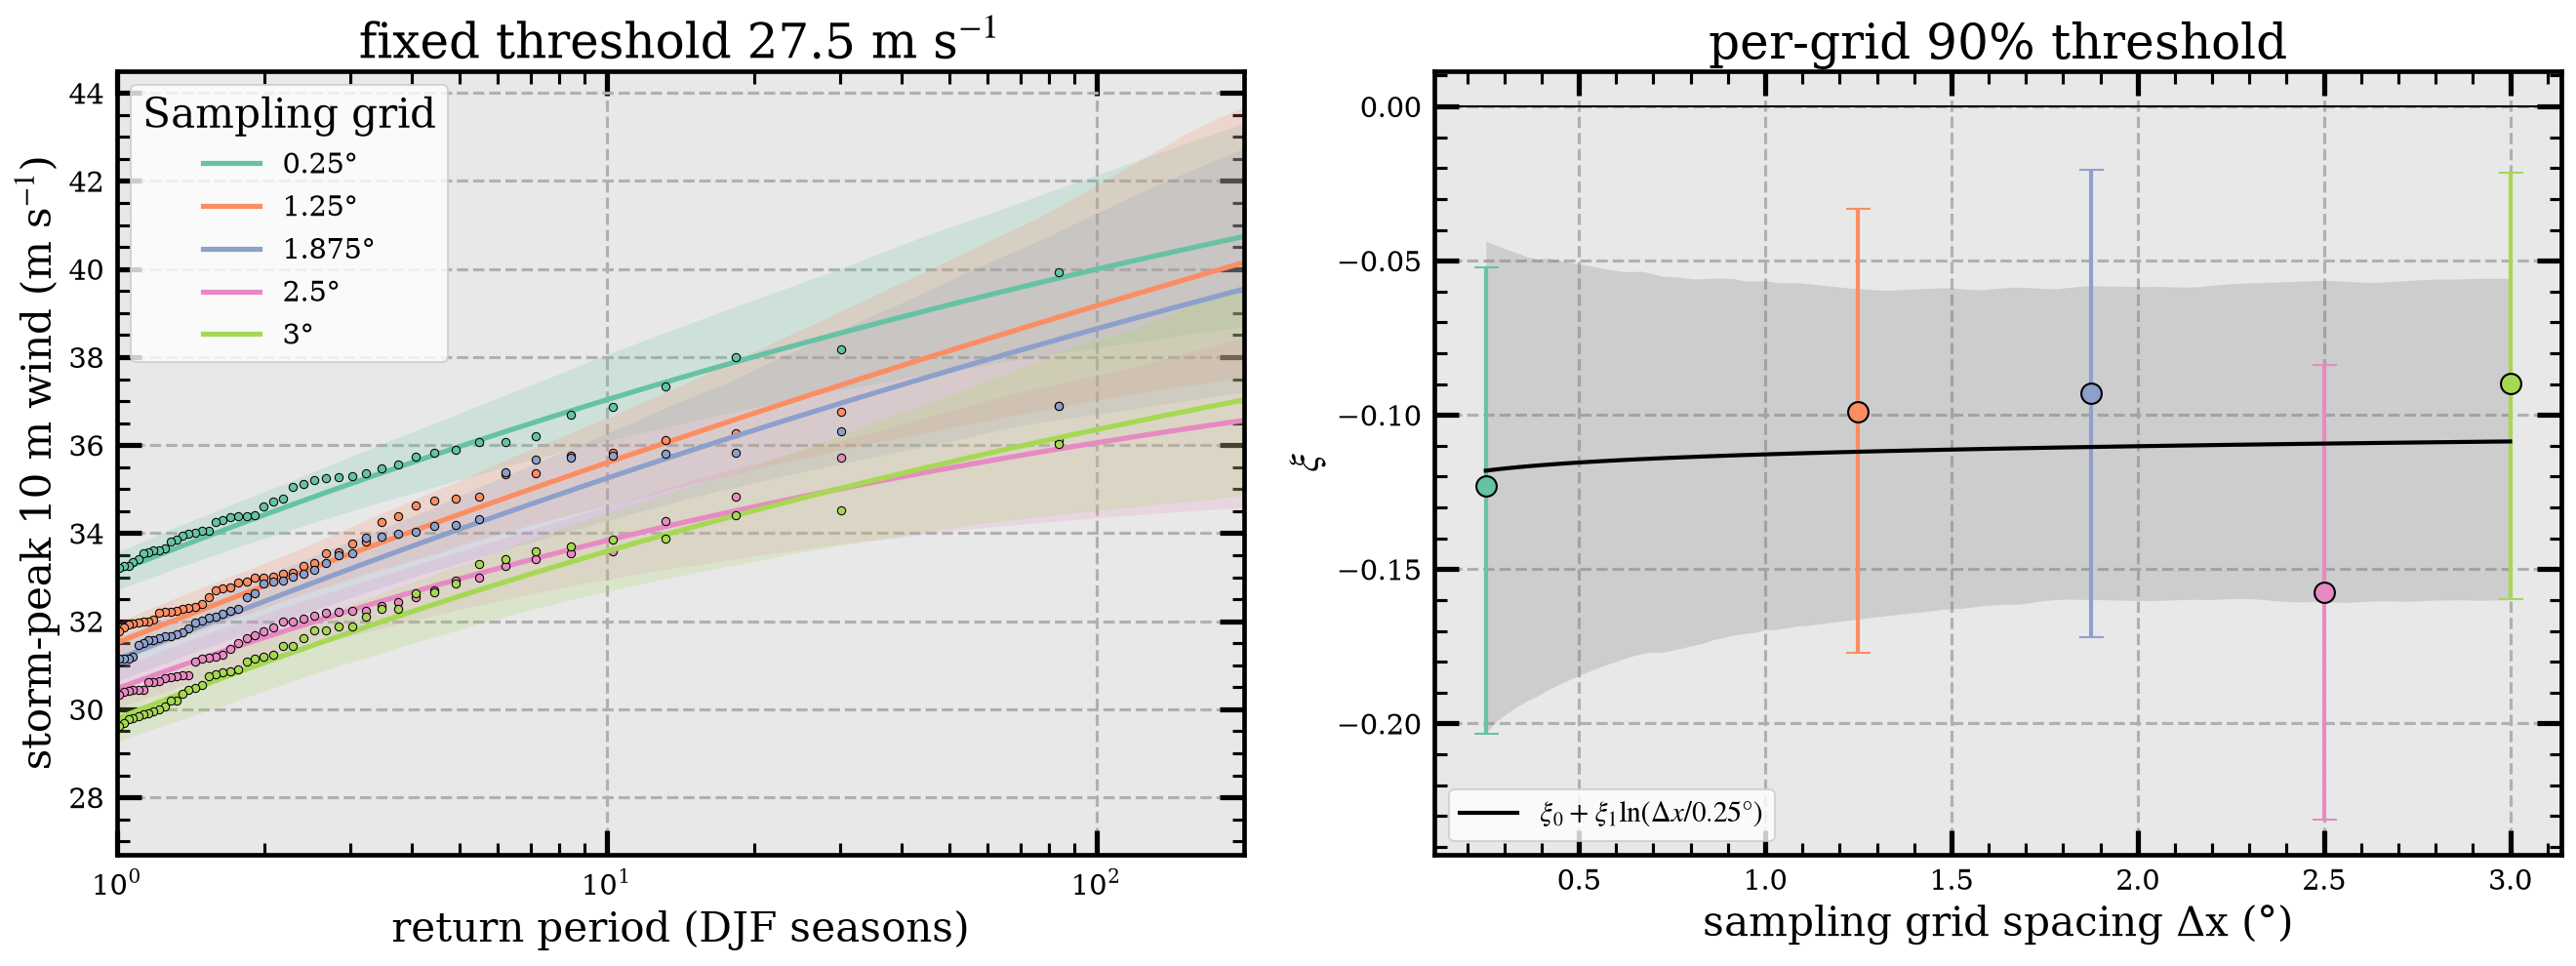

,estimate,2.5%,97.5%
xi0,-0.118,-0.203,-0.044
xi1,0.004,-0.023,0.031
s0,0.959,0.843,1.090
s1,-0.036,-0.082,0.006


In [78]:
T_grid = np.logspace(np.log10(1), np.log10(200), 60)
trend = fit_gpd_trend(peaks, mode="quantile", q=Q_TAIL)
trend_boot = bootstrap(peaks, lambda s: fit_gpd_trend(s, mode="quantile", q=Q_TAIL).to_frame().T).droplevel(1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
for r in RESOLUTIONS:
    f = fits_f.loc[r]
    curves = np.array([return_level(T_grid, b["u"], b["xi"], b["sigma"], b["rate"])
                       for _, b in boot_f.xs(r, level="res").iterrows()])
    ax1.fill_between(T_grid, *np.nanpercentile(curves, [2.5, 97.5], axis=0), color=RES_COLOR[r], alpha=0.2, lw=0)
    ax1.plot(T_grid, return_level(T_grid, f["u"], f["xi"], f["sigma"], f["rate"]), lw=2.5, color=RES_COLOR[r], label=res_label(r))
    top = np.sort(peaks[r])[::-1][: int(f["n_exc"])]
    ax1.plot(N_SEASONS / (np.arange(1, len(top) + 1) - 0.44), top, "o", ms=4, color=RES_COLOR[r], mec="k", mew=0.5)
ax1.set_xscale("log")
ax1.set(xlabel="return period (DJF seasons)", ylabel=VAR_LABEL, xlim=(T_grid[0], T_grid[-1]),
        title=f"fixed threshold {U_FIXED} m s$^{{-1}}$")
ax1.legend(title="Sampling grid")

dx = np.array(RESOLUTIONS)
lo, hi = (boot_q["xi"].astype(float).groupby(level="res").quantile(p) for p in (0.025, 0.975))
for r in RESOLUTIONS:
    xi = fits_q.loc[r, "xi"]
    ax2.errorbar(r, xi, yerr=[[xi - lo[r]], [hi[r] - xi]], fmt="o", ms=10, capsize=6, lw=2, color=RES_COLOR[r], mec="k")
dx_line = np.linspace(dx.min(), dx.max(), 100)
z = np.log(dx_line / NATIVE)
lines = np.array([b["xi0"] + b["xi1"] * z for _, b in trend_boot.iterrows()])
ax2.fill_between(dx_line, *np.percentile(lines, [2.5, 97.5], axis=0), color="grey", alpha=0.25, lw=0)
ax2.plot(dx_line, trend["xi0"] + trend["xi1"] * z, "k-", lw=2, label=r"$\xi_0 + \xi_1 \ln(\Delta x / 0.25°)$")
ax2.axhline(0, color="k", lw=1)
ax2.set(xlabel="sampling grid spacing Δx (°)", ylabel=r"$\xi$", title=f"per-grid {Q_TAIL:.0%} threshold")
ax2.legend()
fig.tight_layout()
plt.show()

trend_point = trend.to_frame("estimate")
trend_point["2.5%"] = trend_boot.quantile(0.025)
trend_point["97.5%"] = trend_boot.quantile(0.975)
trend_point.round(3)

### 7.4 Sensitivity to the threshold and to the resampling unit

The key differences (Δξ and ΔRL20 of the coarsest grid against native) for a few thresholds, and with whole **seasons** resampled instead of storms. Season resampling allows for storms in the same winter being correlated (e.g. through the NAO). Fewer replicates are used here to keep it fast.

In [79]:
N_BOOT_SENS = 300
coarsest = COARSE[-1]
rows = []
for label, kw in ([(f"q = {q:.2f}", {"mode": "quantile", "q": q}) for q in (0.85, 0.90, 0.95)]
                  + [(f"u = {u} m/s", {"mode": "fixed", "u_fixed": u}) for u in (25.0, 27.5, 30.0)]):
    for by in ("storm", "season"):
        stat = lambda s, kw=kw: differences_to_native(fit_all(s, N_SEASONS, **kw)[["xi", "RL20"]].astype(float))
        b = bootstrap(peaks, stat, n_boot=N_BOOT_SENS, by=by).xs(coarsest, level="res")
        point = differences_to_native(fit_all(peaks, N_SEASONS, **kw)[["xi", "RL20"]].astype(float)).loc[coarsest]
        rows.append({"threshold": label, "resample": by,
                     "Δξ": f"{point['xi']:.3f} [{b['xi'].quantile(0.025):.3f}, {b['xi'].quantile(0.975):.3f}]",
                     "ΔRL20 (m/s)": f"{point['RL20']:.2f} [{b['RL20'].quantile(0.025):.2f}, {b['RL20'].quantile(0.975):.2f}]"})
print(f"{res_label(coarsest)} − {res_label(NATIVE)}")
pd.DataFrame(rows).set_index(["threshold", "resample"])

3° − 0.25°


Δξ           ΔRL20 (m/s)
threshold    resample                                               
q = 0.85     storm        0.057 [0.008, 0.113]  -3.39 [-4.18, -2.50]
             season       0.057 [0.021, 0.115]  -3.39 [-3.95, -2.45]
q = 0.90     storm       0.033 [-0.037, 0.107]  -3.47 [-4.47, -2.37]
             season      0.033 [-0.026, 0.100]  -3.47 [-4.24, -2.45]
q = 0.95     storm       0.052 [-0.062, 0.203]  -3.32 [-4.51, -2.00]
             season      0.052 [-0.030, 0.209]  -3.32 [-4.10, -2.03]
u = 25.0 m/s storm        0.097 [0.044, 0.164]  -3.12 [-3.93, -2.22]
             season       0.097 [0.041, 0.154]  -3.12 [-3.77, -2.21]
u = 27.5 m/s storm      -0.019 [-0.165, 0.112]  -3.50 [-4.49, -2.73]
             season     -0.019 [-0.183, 0.133]  -3.50 [-4.29, -2.39]
u = 30.0 m/s storm     -0.249 [-0.970, -0.065]  -3.34 [-4.35, -2.70]
             season    -0.249 [-0.953, -0.045]  -3.34 [-4.03, -2.51]

## 8. Points for the write-up

* **Representation, not modelling:** the coarse fields are the same ERA5 field, bilinearly remapped. The results quantify how storm peaks change when the field is *represented* on a coarser grid, not how a coarse model would simulate them.
* **Bilinear vs conservative:** bilinear remapping samples the field more sparsely. Conservative (area-mean) remapping is closer to what a coarse model's grid value means, and would attenuate the peaks more strongly.
* **Sub-sampling vs interpolation:** on 1.25°, 2.5° and 3° the coarse points coincide with native points, so remapping is pure sub-sampling and the result depends on where the grid starts (a grid shifted by half a cell would give different storm peaks). Shifting the grid origin would show how large this alignment noise is. Only on 1.875° does `u10`/`v10` interpolation (and component cancellation) play a role; to separate it, remap `ws10` itself and compare.
* **ERA5 is already smooth:** its effective resolution is several grid lengths, and it underestimates peak winds in compact, intense storms. The losses here are therefore relative to an already smoothed field.
* **Few points at coarse grids:** see section 3.3. At 3° the storm peak is a maximum over about ten values, so grid alignment adds noise.
* **Negative ξ:** for ξ > −0.5 the MLE and asymptotic intervals are regular. If a fit goes below that, rely on the bootstrap and the moment estimator only.

## 9. Results of the run of 2026-11-20 (28 DJF seasons 1998/99–2025/26, 3362 storms, `ws10_max_max`)

These numbers are copied from the outputs above. Update them if the data, `Q_TAIL`, `U_FIXED` or `N_BOOT` change.

* **Pipeline check passed:** no coarse peak exceeds the native peak, apart from 2 storms at 1.875° (by ≤ 0.011 m s⁻¹, a circle-edge effect).
* **Size of the attenuation:** the median ratio R is 0.963, 0.937, 0.925 and 0.908 at 1.25°, 1.875°, 2.5° and 3°. That is a median loss of 0.7, 1.3, 1.5 and 1.9 m s⁻¹. The fraction of storms reaching storm force (≥ 24.5 m s⁻¹) falls from 0.235 to 0.107 at 3°.
* **Does it grow with intensity?** Over most of the range R is flat, so the loss is roughly proportional to the intensity (slope ≈ 0). The **strongest storms** lose more: median R in the top 10 % minus the middle half is −0.025 [−0.034, −0.014] at 2.5° and −0.033 [−0.047, −0.021] at 3°, and −0.045 [−0.059, −0.029] for the top 5 % at 3°. At 1.25° the effect is small (−0.012) and at 1.875° it is not significant. In absolute terms, the strongest storms lose about 5 m s⁻¹ at 3°, against about 2 m s⁻¹ for a typical storm. The weakest decile also has slightly lower R.
* **Tail shape:** ξ ≈ −0.10 at native and −0.11 to −0.14 on the coarse grids: a light tail with a weak bound at every grid. All Δξ intervals include 0, and the trend is ξ₁ = −0.014 [−0.047, 0.031] per e-fold of Δx. There is **no evidence that coarsening makes the tail more bounded**, and ξ is far from −1, so there is **no pile-up** against a ceiling. The implied endpoints (41–53 m s⁻¹) are far above the observed maxima and very uncertain.
* **Return levels:** the 20-season storm peak drops by 1.7 [0.6, 2.4], 2.1 [0.9, 3.0], 3.7 [2.1, 5.4] and 4.6 [3.1, 6.0] m s⁻¹ (per-grid 90 % thresholds). The fixed 27.5 m s⁻¹ threshold gives similar numbers at 2.5° and 3°. There, the number of storms per season above 27.5 m s⁻¹ falls from 11.9 to 2.9 at 3°.
* **Robustness:** the 3° drop in the 20-season level is −3.9 to −4.6 m s⁻¹ for all thresholds tested, and for both storm and season resampling. Δξ is never significant, except at u = 30 m s⁻¹. That case has only about 25 exceedances at 3°, so it is not reliable.
* **ξ depends on the threshold:** in the stability plots, ξ rises from about −0.2 at the 70th percentile to about −0.1 at the 90th, at every grid. The paired differences are much less affected than the absolute values.

**In short:** coarser sampling lowers the storm peaks by about 4–9 %. The strongest few percent of storms lose more on the 2.5° and 3° grids, so the high return levels drop by up to about 4.5 m s⁻¹. But the shape of the tail (ξ) does not change detectably, and there is no accumulation at a common cap. The extra loss at the top is a compression of the strongest storms (compact wind maxima missed by a few coarse points), not a new bound.